# Seasonal Variation using Diffusion Interpolation (v2)

This notebook visualizes the seasonal variation of Dissolved Oxygen using the physics-based steady-state diffusion interpolation method.

In [2]:
# --- 1. Imports ---
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import scipy.ndimage as ndimage
import logging
from shapely.geometry import Point
import sys
from pathlib import Path

# Ensure paths import
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

## 2. Parameters (The "Control Panel")

In [3]:
# --- Parameters ---
season = 'Summer'
layer = 'bottom'
target_year = '1991'

## 3. Data Loading & Preprocessing

In [4]:
# 1. Load Custom Boundary Shapefiles (WGS84)
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water_boundary = gpd.read_file(water_boundary_path)
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary.shp"
sis_land_boundary = gpd.read_file(land_boundary_path)

if sis_water_boundary.crs != "EPSG:4326":
    sis_water_boundary = sis_water_boundary.to_crs("EPSG:4326")
if sis_land_boundary.crs != "EPSG:4326":
    sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

bounds = sis_water_boundary.total_bounds

# 2. Project water mask to UTM Zone 53N to define the computation grid
utm_crs = 'EPSG:32653'
sis_water_utm = sis_water_boundary.to_crs(utm_crs)
bounds_utm = sis_water_utm.total_bounds

# 3. Create grid (2000m resolution)
GRID_RES = 2000
grid_x_1d = np.arange(bounds_utm[0], bounds_utm[2], GRID_RES)
grid_y_1d = np.arange(bounds_utm[1], bounds_utm[3], GRID_RES)
grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)

pts = gpd.GeoSeries([Point(x, y) for x, y in zip(grid_x.flatten(), grid_y.flatten())], crs=utm_crs)
water_polygon = sis_water_utm.geometry.union_all()
valid_points_mask = pts.within(water_polygon)
water_mask = np.zeros(grid_x.shape, dtype=bool)
water_mask.flat = valid_points_mask.values

# Transform all points to WGS84 for Cartopy mapping
all_points_gdf = gpd.GeoDataFrame(
    geometry=[Point(x, y) for x, y in zip(grid_x.flatten(), grid_y.flatten())],
    crs=utm_crs
).to_crs(epsg=4326)

lon_wgs = all_points_gdf.geometry.x.values.reshape(grid_x.shape)
lat_wgs = all_points_gdf.geometry.y.values.reshape(grid_y.shape)

In [5]:
# 4. Diffusion Interpolation Solver
def run_diffusion_interpolation(year_data, station_locs_gdf, grid_x_1d, grid_y_1d, water_mask, grid_x, grid_y, max_iters=2000, tol=1e-4, omega=1.7):
    # Initialize the solution grid with NaNs (Land will remain NaN)
    Z = np.full(water_mask.shape, np.nan)
    
    # Provide an initial guess for water cells (e.g., mean observed DO)
    mean_val = year_data['do_'].mean()
    Z[water_mask] = mean_val
    
    # Create mask to track fixed observation cells
    fixed_mask = np.zeros_like(water_mask, dtype=bool)
    
    # Map observations to the nearest grid cell
    for idx, row in year_data.iterrows():
        station_id = idx
        if station_id in station_locs_gdf.index:
            pt = station_locs_gdf.loc[station_id].geometry
            # Find closest grid indices
            ix = np.argmin(np.abs(grid_x_1d - pt.x))
            iy = np.argmin(np.abs(grid_y_1d - pt.y))
            
            # Snap to grid if it's considered water
            if water_mask[iy, ix]:
                Z[iy, ix] = row['do_']
                fixed_mask[iy, ix] = True
            else:
                dist = (grid_x - pt.x)**2 + (grid_y - pt.y)**2
                dist[~water_mask] = np.inf
                nearest_water_flat_idx = np.argmin(dist)
                iy_nearest, ix_nearest = np.unravel_index(nearest_water_flat_idx, water_mask.shape)
                Z[iy_nearest, ix_nearest] = row['do_']
                fixed_mask[iy_nearest, ix_nearest] = True

    # Red-Black masks
    i_indices, j_indices = np.indices(Z.shape)
    red_mask = (i_indices + j_indices) % 2 == 0
    black_mask = ~red_mask

    kernel = np.array([[0, 1, 0], 
                       [1, 0, 1], 
                       [0, 1, 0]])
                       
    water_float = water_mask.astype(float)
    W = ndimage.convolve(water_float, kernel, mode='constant', cval=0.0)
    
    def update(Z_current, mask):
        Z_water = np.nan_to_num(Z_current, copy=True, nan=0.0) * water_mask
        Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
        with np.errstate(divide='ignore', invalid='ignore'):
            Z_new = np.where(W > 0, Z_sum / W, Z_current)
            
        update_mask = mask & water_mask & (~fixed_mask)
        Z_current[update_mask] = (1 - omega) * Z_current[update_mask] + omega * Z_new[update_mask]
        return Z_current

    for it in range(max_iters):
        Z_old = Z.copy()
        Z = update(Z, red_mask)
        Z = update(Z, black_mask)
        diff = np.abs(Z[water_mask] - Z_old[water_mask])
        max_diff = np.nanmax(diff) if len(diff) > 0 else 0
        if max_diff < tol:
            break
            
    return Z

In [6]:
# 5. Extract Station Locations
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
stations_gdf = merged_gdf[['zettaicode', 'longitude', 'latitude']].drop_duplicates().set_index('zettaicode')
stations_utm = gpd.GeoDataFrame(
    stations_gdf,
    geometry=[Point(xy) for xy in zip(stations_gdf.longitude, stations_gdf.latitude)],
    crs='EPSG:4326'
).to_crs(utm_crs)

In [7]:
# Helper function to load data
def load_year_data(s, l, y):
    subset_dir = ProjectPaths.get_subset_dir(s, l)
    yearly_do_file = subset_dir / "yearly_do_df.csv"
    if not yearly_do_file.exists():
        return None
    yearly_do_df = pd.read_csv(yearly_do_file, dtype={'zettaicode': str}).set_index('zettaicode')
    if str(y) in yearly_do_df.columns:
        y_col = str(y)
    elif int(y) in yearly_do_df.columns:
        y_col = int(y)
    else:
        return None
    do_values = yearly_do_df[[y_col]].dropna().rename(columns={y_col: 'do_'})
    return do_values

## 4. Single Map Visualization
Single map for a single year for a single parameter (DO)

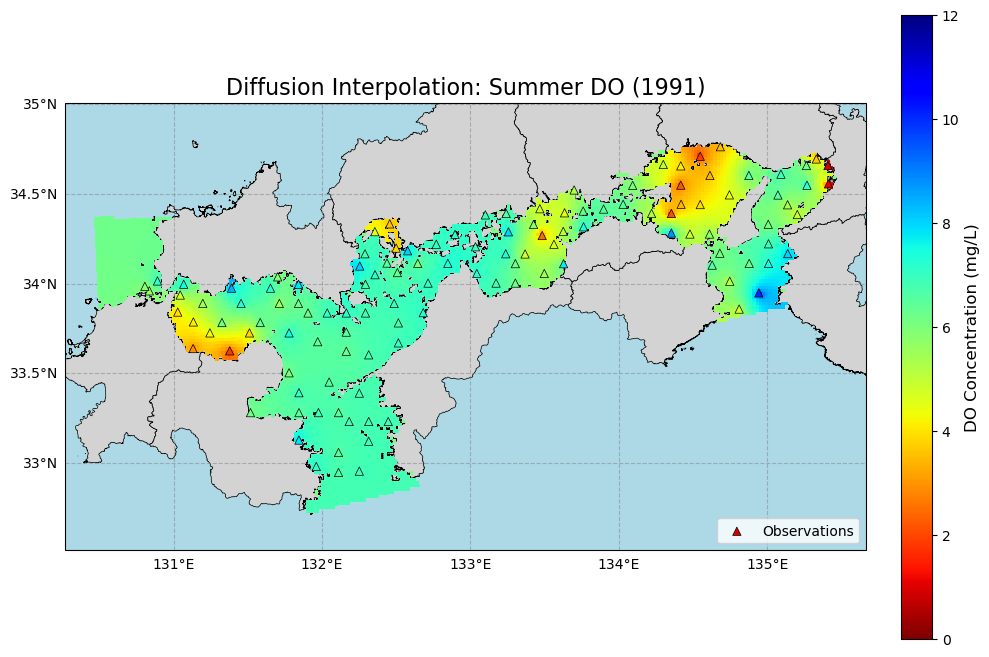

In [8]:
# Load data for target year/season
do_values = load_year_data(season, layer, target_year)
if do_values is not None:
    # Run interpolation
    Z = run_diffusion_interpolation(do_values, stations_utm, grid_x_1d, grid_y_1d, water_mask, grid_x, grid_y)
    
    # Plotting
    var_cfg = MappingConfig.get_var_settings('do_')
    vmin = var_cfg['vmin']
    vmax = var_cfg['vmax']
    cmap = var_cfg['cmap']
    label = var_cfg['label']
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    sis_land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, linewidth=MappingConfig.LINEWIDTH_LAND,
                      transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)
    
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot interpolated data
    c_m = ax.pcolormesh(lon_wgs, lat_wgs, Z, transform=ccrs.PlateCarree(), cmap=cmap, shading='nearest', zorder=MappingConfig.ZORDER_PREDICTED, vmin=vmin, vmax=vmax)
    
    # Plot observations
    plot_df = do_values.join(stations_gdf, how='inner')
    ax.scatter(plot_df['longitude'], plot_df['latitude'], c=plot_df['do_'], cmap=cmap,
               edgecolors='black', linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS, marker='^', vmin=vmin, vmax=vmax, label='Observations')
    
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())
    
    cbar = plt.colorbar(c_m, ax=ax, fraction=0.036, pad=0.04)
    cbar.set_label(label, fontsize=12)
    plt.title(f'Diffusion Interpolation: {season} DO ({target_year})', fontsize=16)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

## 5. 2x2 Layout: Four Seasons in a Specific Year

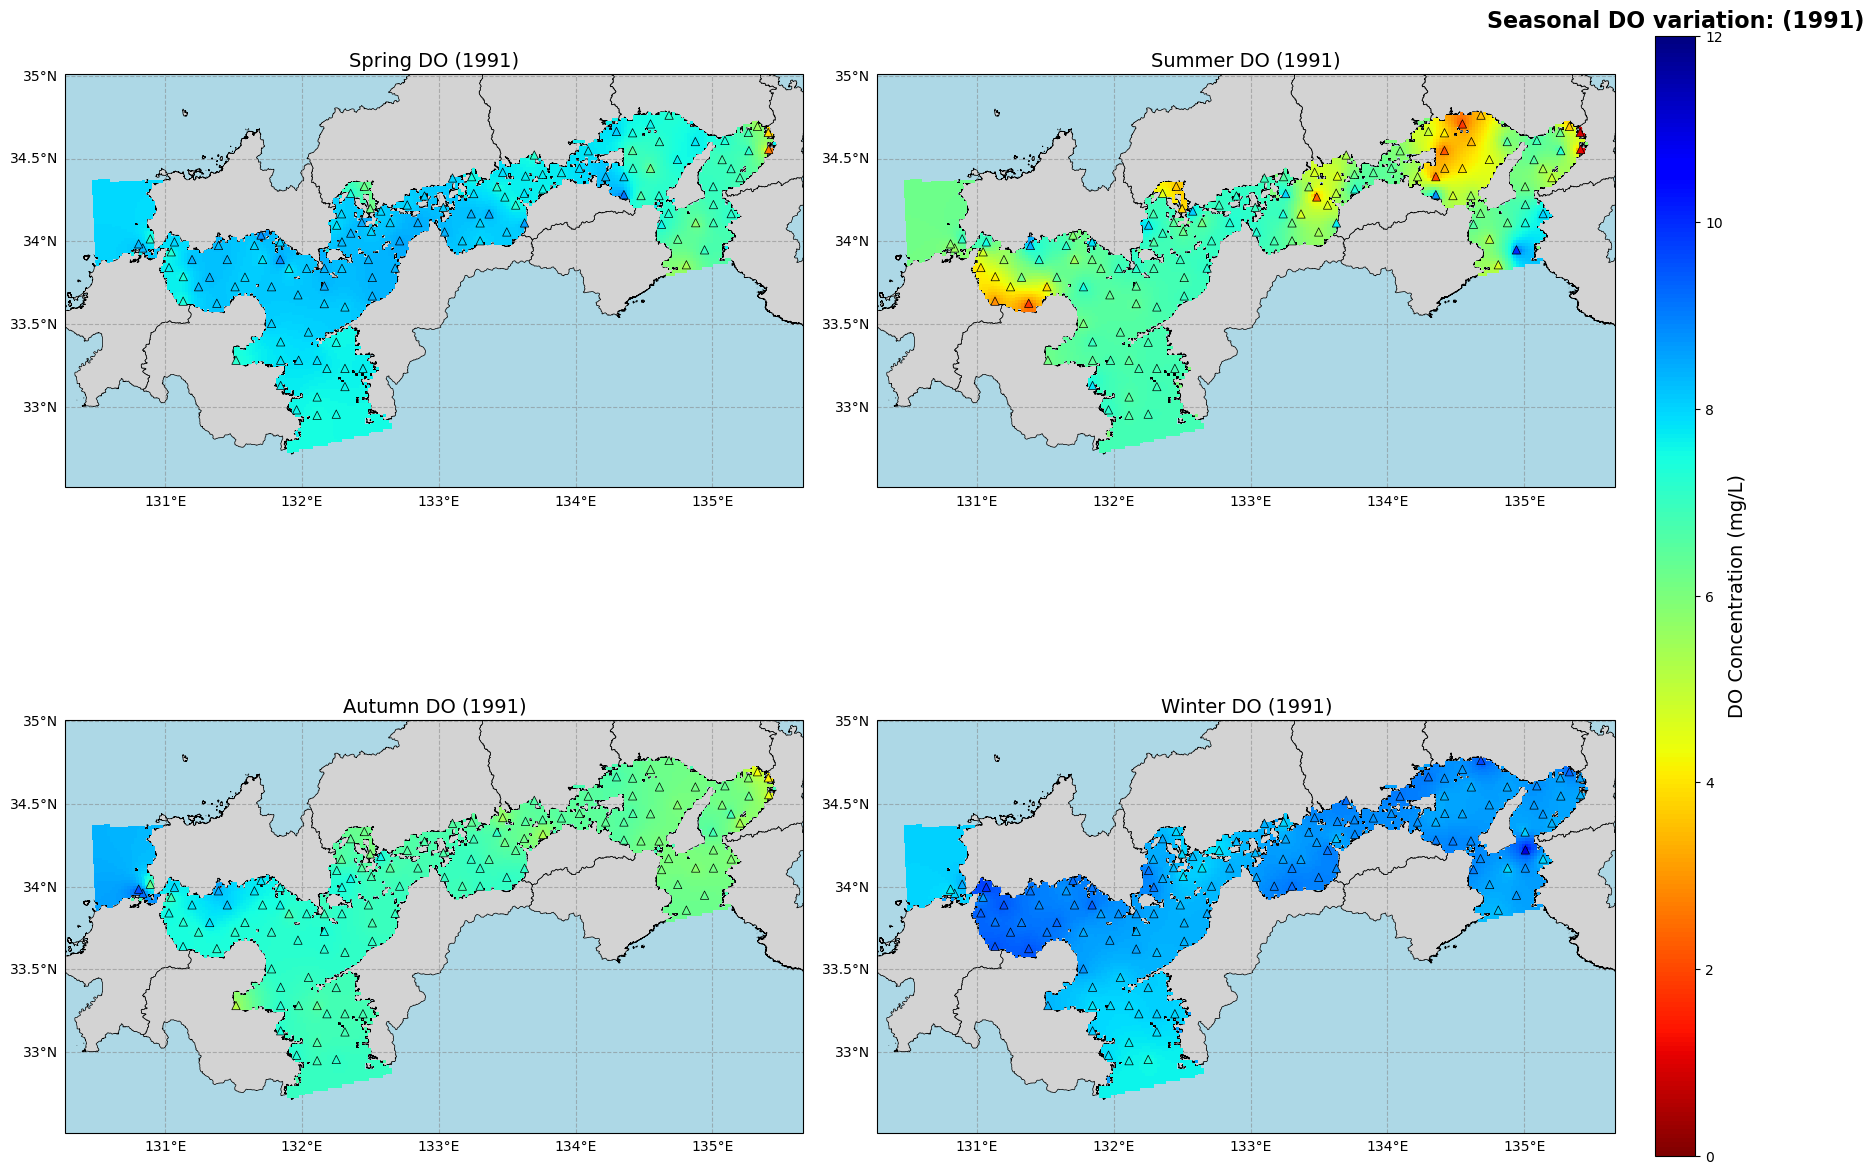

In [ ]:
seasons = ['Spring', 'Summer', 'Autumn', 'Winter']
fig, axes = plt.subplots(2, 2, figsize=(20, 16), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

# Shared colorbar limits
var_cfg = MappingConfig.get_var_settings('do_')
vmin = var_cfg['vmin']
vmax = var_cfg['vmax']
cmap = var_cfg['cmap']
label = var_cfg['label']

for i, s in enumerate(seasons):
    ax = axes[i]
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    sis_land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, linewidth=MappingConfig.LINEWIDTH_LAND,
                      transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)
                      
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())
    
    do_values = load_year_data(s, layer, target_year)
    if do_values is not None:
        Z = run_diffusion_interpolation(do_values, stations_utm, grid_x_1d, grid_y_1d, water_mask, grid_x, grid_y)
        c_m = ax.pcolormesh(lon_wgs, lat_wgs, Z, transform=ccrs.PlateCarree(), cmap=cmap, shading='nearest', zorder=MappingConfig.ZORDER_PREDICTED, vmin=vmin, vmax=vmax)
        
        plot_df = do_values.join(stations_gdf, how='inner')
        ax.scatter(plot_df['longitude'], plot_df['latitude'], c=plot_df['do_'], cmap=cmap,
                   edgecolors='black', linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS, marker='^', vmin=vmin, vmax=vmax)
                   
    ax.set_title(f'{s} DO ({target_year})', fontsize=14)

# Create a single colorbar for all subplots
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(c_m, cax=cbar_ax)
cbar.set_label(label, fontsize=14)

plt.title(f'Seasonal DO variation: ({target_year})', fontsize=16, fontweight='bold')
plt.subplots_adjust(right=0.9, wspace=0.1, hspace=0.1)
plt.show()

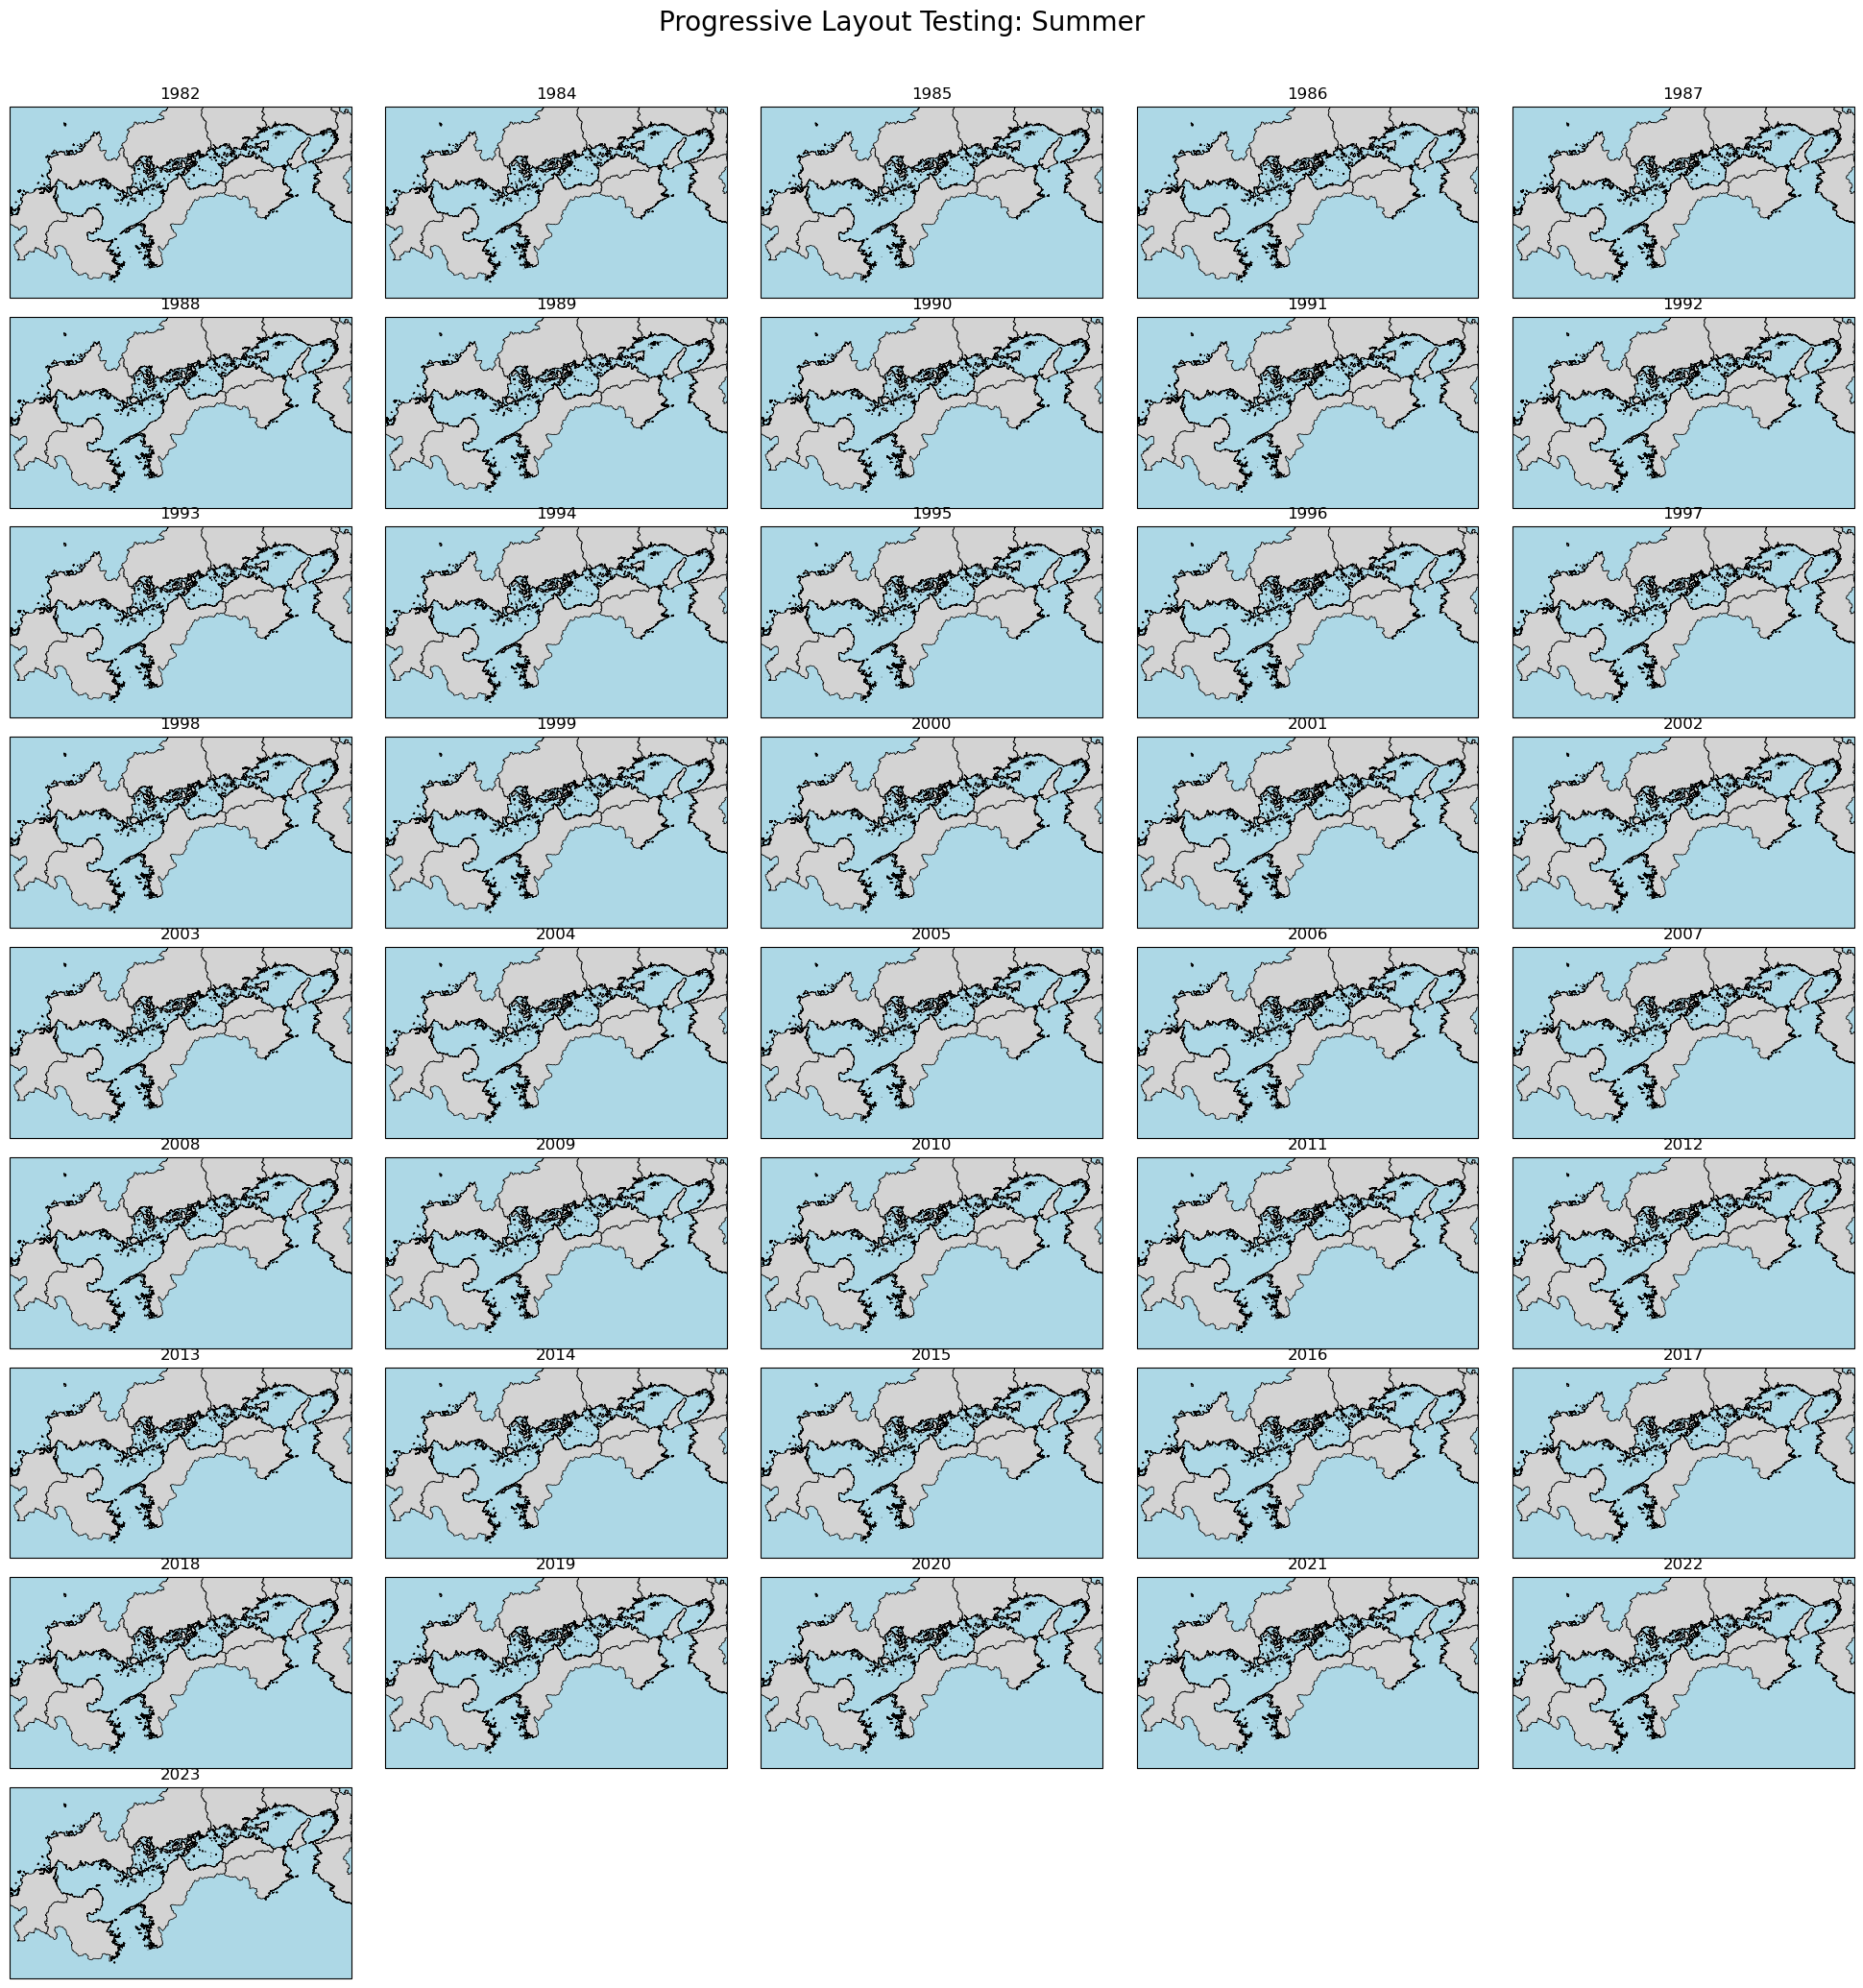

In [10]:
# --- New Cell: Layout Testing (No Interpolation) ---
# Determine available years for the target season
subset_dir = ProjectPaths.get_subset_dir(season, layer)
yearly_do_file = subset_dir / "yearly_do_df.csv"
yearly_do_df = pd.read_csv(yearly_do_file, dtype={'zettaicode': str}).set_index('zettaicode')
available_years = sorted([col for col in yearly_do_df.columns if str(col).isdigit()])

n_years = len(available_years)
n_cols = 5
n_rows = int(np.ceil(n_years / n_cols))

# Dynamically calculate figsize based on the extent to remove Cartopy vertical padding
extent = [bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2]
aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])

fig_width = 25
width_per_subplot = fig_width / n_cols
height_per_subplot = (width_per_subplot * aspect_ratio) + 0.5 # Adds a small padding buffer
fig_height = height_per_subplot * n_rows

fig, axes = plt.subplots(n_rows, n_cols, figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

for i, y in enumerate(available_years):
    ax = axes[i]
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    sis_land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, 
                           linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)
                      
    ax.set_extent(extent, crs=ccrs.PlateCarree())
                   
    ax.set_title(f'{y}', fontsize=12)
    
    # Hide axes ticks for aesthetics
    ax.set_xticks([])
    ax.set_yticks([])

# Destroy any empty subplots in the grid 
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f'Progressive Layout Testing: {season}', fontsize=20, y=0.92)
plt.subplots_adjust(right=0.9, wspace=0.05, hspace=0.1)
plt.show()


## 6. Progressive Seasonal Subplots (All Years for a Single Season)

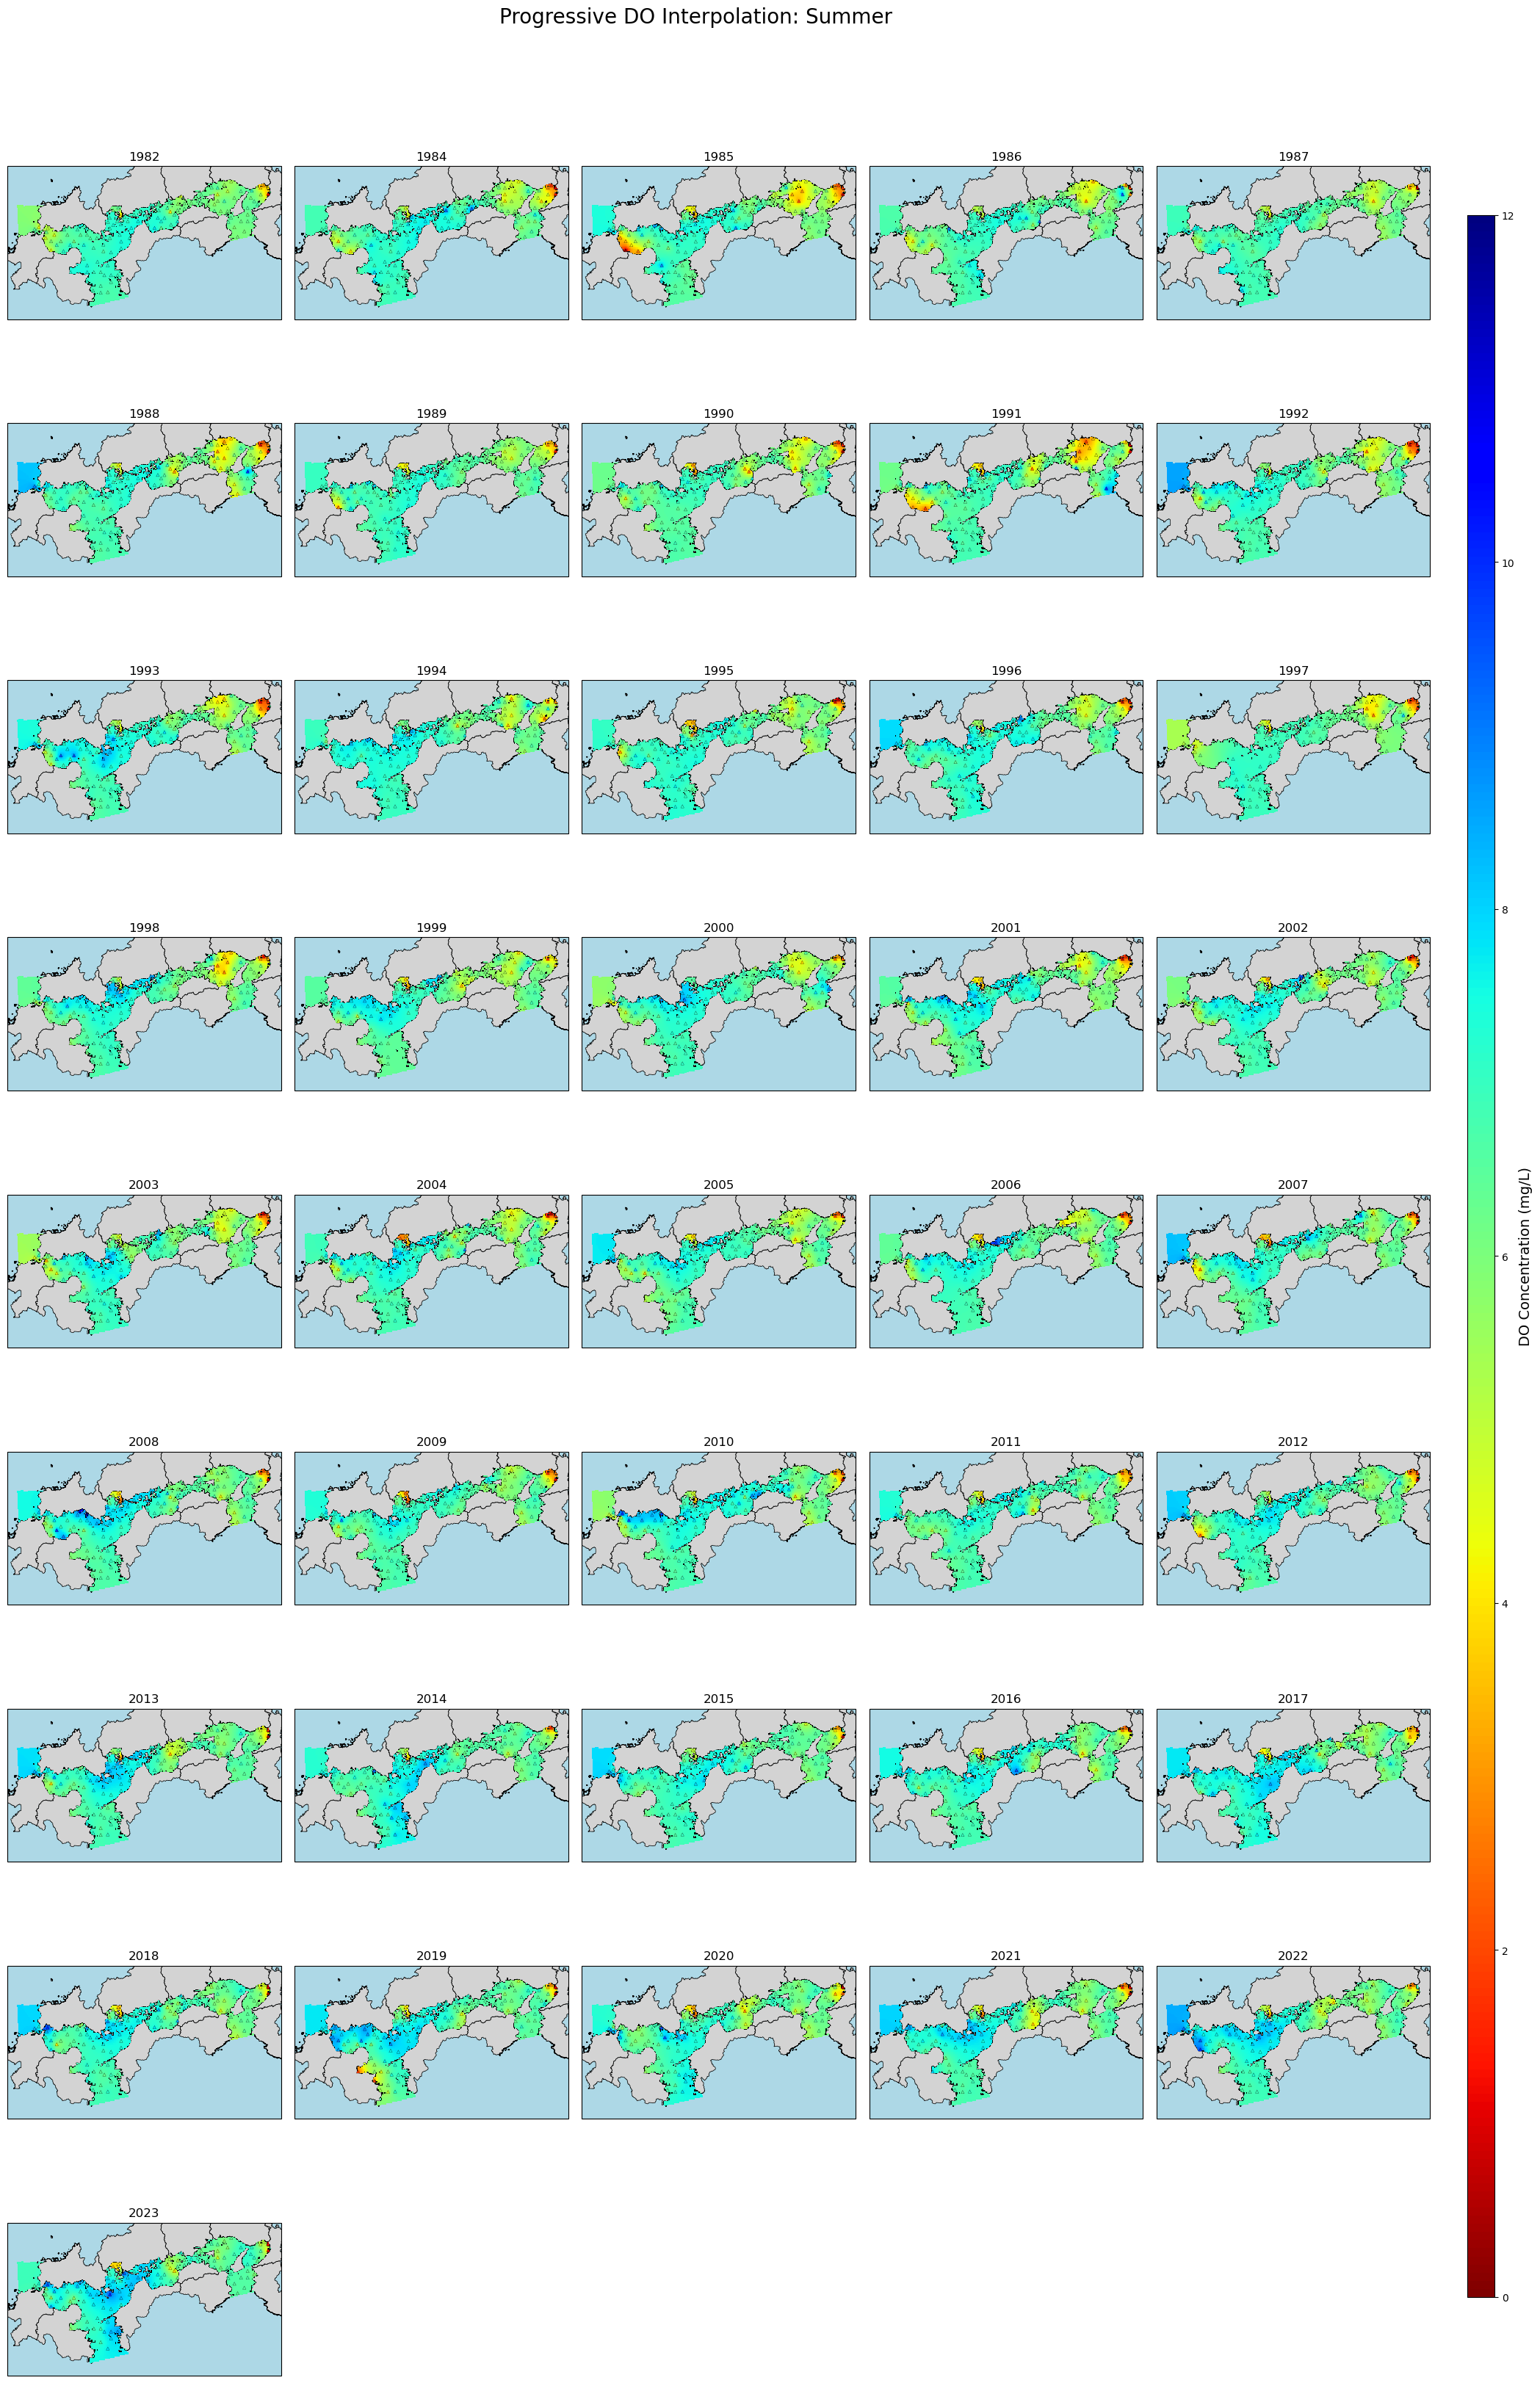

In [9]:
# Determine available years for the target season
subset_dir = ProjectPaths.get_subset_dir(season, layer)
yearly_do_file = subset_dir / "yearly_do_df.csv"
yearly_do_df = pd.read_csv(yearly_do_file, dtype={'zettaicode': str}).set_index('zettaicode')
available_years = sorted([col for col in yearly_do_df.columns if str(col).isdigit()])

n_years = len(available_years)
n_cols = 5
n_rows = int(np.ceil(n_years / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(25, 4.5 * n_rows), subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

var_cfg = MappingConfig.get_var_settings('do_')
vmin = var_cfg['vmin']
vmax = var_cfg['vmax']
cmap = var_cfg['cmap']
label = var_cfg['label']

for i, y in enumerate(available_years):
    ax = axes[i]
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    
    sis_land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, linewidth=MappingConfig.LINEWIDTH_LAND,
                      transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)
                      
    ax.set_extent([bounds[0]-0.2, bounds[2]+0.2, bounds[1]-0.2, bounds[3]+0.2], crs=ccrs.PlateCarree())
    
    do_values = yearly_do_df[[y]].dropna().rename(columns={y: 'do_'})
    if len(do_values) > 0:
        Z = run_diffusion_interpolation(do_values, stations_utm, grid_x_1d, grid_y_1d, water_mask, grid_x, grid_y)
        c_m = ax.pcolormesh(lon_wgs, lat_wgs, Z, transform=ccrs.PlateCarree(), cmap=cmap, shading='nearest', zorder=MappingConfig.ZORDER_PREDICTED, vmin=vmin, vmax=vmax)
        
        plot_df = do_values.join(stations_gdf, how='inner')
        ax.scatter(plot_df['longitude'], plot_df['latitude'], c=plot_df['do_'], cmap=cmap,
                   edgecolors='black', linewidth=0.2, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS, marker='^', s=10, vmin=vmin, vmax=vmax)
                   
    ax.set_title(f'{y}', fontsize=12)
    
    # Hide axis
    ax.set_xticks([])
    ax.set_yticks([])

# Remove unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Single colorbar
if n_years > 0:
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
    cbar = fig.colorbar(c_m, cax=cbar_ax)
    cbar.set_label(label, fontsize=14)

plt.suptitle(f'Progressive DO Interpolation: {season}', fontsize=20, y=0.92)
plt.subplots_adjust(right=0.9, wspace=0.05, hspace=0.1)
plt.show()